In [7]:
# ============================================================
# ViT-B/16 — CELL 1
# Install + Imports + Configuration
# Shared-Drive Shortcut Friendly Dataset Detection
# + Output Folders
# ============================================================


# ============================================================
# 0. INSTALL PACKAGES
# ============================================================

!pip -q install -U timm fvcore scipy statsmodels openpyxl


# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=False
)


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms

from torchvision.transforms import (
    InterpolationMode
)

import timm

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings(
    "ignore"
)


# ============================================================
# 2. SAME EXPERIMENTAL CONFIGURATION
# ============================================================

SEED = 42

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 30

LEARNING_RATE = 1e-4

N_FOLDS = 5

THRESHOLD = 0.50

NUM_WORKERS = 2


# ============================================================
# 3. MODEL INFORMATION
# ============================================================

MODEL_NAME = "ViT-B/16"

TIMM_MODEL_NAME = (
    "vit_base_patch16_224.augreg_in21k_ft_in1k"
)

MODEL_FOLDER_NAME = (
    "06_ViT_B16"
)


# ============================================================
# 4. CLASS INFORMATION
# ============================================================

CLASS_NAMES = [
    "encroachment_present",
    "no_encroachment"
]

CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# ============================================================
# 5. SEARCH POSSIBLE DRIVE LOCATIONS
# ============================================================

SEARCH_LOCATIONS = [

    Path(
        "/content/drive/MyDrive"
    ),

    Path(
        "/content/drive/.shortcut-targets-by-id"
    )
]


DATASET_DIR = None


print(
    "=" * 75
)

print(
    "SEARCHING FOR ACTUAL DATASET"
)

print(
    "=" * 75
)


# ============================================================
# 6. FIND DIRECTORY CONTAINING BOTH CLASS FOLDERS
# ============================================================

for search_root in SEARCH_LOCATIONS:

    if not search_root.exists():

        print(
            "Skipping unavailable location:"
        )

        print(
            search_root
        )

        continue


    print(
        "\nSearching inside:"
    )

    print(
        search_root
    )


    try:

        encroachment_folders = (
            search_root.rglob(
                "encroachment_present"
            )
        )


        for encroachment_folder in (
            encroachment_folders
        ):

            if not encroachment_folder.is_dir():

                continue


            candidate_dataset_dir = (
                encroachment_folder.parent
            )


            no_encroachment_folder = (
                candidate_dataset_dir /
                "no_encroachment"
            )


            if not no_encroachment_folder.is_dir():

                continue


            # -----------------------------------------------
            # Confirm both folders actually contain images
            # -----------------------------------------------

            encroachment_count = sum(

                1

                for file_path in
                encroachment_folder.rglob("*")

                if (
                    file_path.is_file()
                    and
                    file_path.suffix.lower()
                    in IMAGE_EXTENSIONS
                )
            )


            no_encroachment_count = sum(

                1

                for file_path in
                no_encroachment_folder.rglob("*")

                if (
                    file_path.is_file()
                    and
                    file_path.suffix.lower()
                    in IMAGE_EXTENSIONS
                )
            )


            if (
                encroachment_count > 0
                and
                no_encroachment_count > 0
            ):

                DATASET_DIR = (
                    candidate_dataset_dir
                )

                break


    except Exception as search_error:

        print(
            "Could not fully search:"
        )

        print(
            search_root
        )

        print(
            "Reason:",
            search_error
        )


    if DATASET_DIR is not None:

        break


# ============================================================
# 7. FINAL DATASET CHECK
# ============================================================

if DATASET_DIR is None:

    raise FileNotFoundError(
        "\nDataset could not be located.\n\n"
        "The code searched Google Drive for a directory "
        "containing BOTH class folders:\n\n"
        "encroachment_present\n"
        "no_encroachment\n\n"
        "Since Brishty_ml is a Shared-with-me shortcut, "
        "make sure the shortcut is available to the same "
        "Google account mounted in Colab."
    )


print(
    "\nDataset successfully detected."
)


print(
    "\nActual DATASET_DIR:"
)

print(
    DATASET_DIR
)


# ============================================================
# 8. COUNT DATASET IMAGES
# ============================================================

class_image_counts = {}

total_images = 0


for class_name in CLASS_NAMES:

    class_folder = (
        DATASET_DIR /
        class_name
    )


    image_count = sum(

        1

        for file_path in
        class_folder.rglob("*")

        if (
            file_path.is_file()
            and
            file_path.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    )


    class_image_counts[
        class_name
    ] = image_count


    total_images += (
        image_count
    )


    if image_count == 0:

        raise RuntimeError(
            f"No images found inside:\n"
            f"{class_folder}"
        )


# ============================================================
# 9. OUTPUT ROOT
# ============================================================

# IMPORTANT:
# Results are saved in YOUR MyDrive,
# not inside the shared shortcut.

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "reviewer_final_results"
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 10. MODEL-SPECIFIC OUTPUT FOLDERS
# ============================================================

MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    MODEL_FOLDER_NAME
)


MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)


HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)


FIGURE_DIR = (
    MODEL_OUTPUT_DIR /
    "figures"
)


PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)


METRIC_DIR = (
    MODEL_OUTPUT_DIR /
    "metrics"
)


for folder in [

    MODEL_OUTPUT_DIR,

    MODEL_DIR,

    HISTORY_DIR,

    FIGURE_DIR,

    PREDICTION_DIR,

    METRIC_DIR

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 11. FIXED SPLIT PATHS
# ============================================================

COMPLETE_SPLIT_PATH = (
    OUTPUT_DIR /
    "fixed_test_and_5fold_split.csv"
)


FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)


TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)


# ============================================================
# 12. DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# 13. REPRODUCIBILITY
# ============================================================

def set_seed(
    seed=42
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(
        seed
    )


    random.seed(
        seed
    )


    np.random.seed(
        seed
    )


    torch.manual_seed(
        seed
    )


    torch.cuda.manual_seed_all(
        seed
    )


    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed(
    SEED
)


# ============================================================
# 14. FINAL CELL CHECK
# ============================================================

print(
    "\n" +
    "=" * 75
)

print(
    "ViT-B/16 CELL 1 COMPLETED"
)

print(
    "=" * 75
)


print(
    "Device:",
    DEVICE
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(
            0
        )
    )


print(
    "\nModel:",
    MODEL_NAME
)


print(
    "Checkpoint:",
    TIMM_MODEL_NAME
)


print(
    "\nActual detected dataset directory:"
)

print(
    DATASET_DIR
)


print(
    "\nDataset class counts:"
)


for class_name in CLASS_NAMES:

    print(
        f"{class_name}: "
        f"{class_image_counts[class_name]}"
    )


print(
    "Total images:",
    total_images
)


print(
    "\nExperimental Configuration"
)


print(
    "Image size:",
    IMG_SIZE
)


print(
    "Batch size:",
    BATCH_SIZE
)


print(
    "Epochs:",
    EPOCHS
)


print(
    "Learning rate:",
    LEARNING_RATE
)


print(
    "Number of folds:",
    N_FOLDS
)


print(
    "Number of workers:",
    NUM_WORKERS
)


print(
    "\nFixed development split:"
)

print(
    FOLD_CSV_PATH
)


print(
    "\nFixed test split:"
)

print(
    TEST_CSV_PATH
)


print(
    "\nViT-B/16 output folder:"
)

print(
    MODEL_OUTPUT_DIR
)


print(
    "\nNo fold has been trained yet."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SEARCHING FOR ACTUAL DATASET

Searching inside:
/content/drive/MyDrive

Searching inside:
/content/drive/.shortcut-targets-by-id

Dataset successfully detected.

Actual DATASET_DIR:
/content/drive/.shortcut-targets-by-id/1o640b3cpJ1dmNlo2jud8fYyofekmn67l/clean_dataset_brishty/images

ViT-B/16 CELL 1 COMPLETED
Device: cuda
GPU: Tesla T4

Model: ViT-B/16
Checkpoint: vit_base_patch16_224.augreg_in21k_ft_in1k

Actual detected dataset directory:
/content/drive/.shortcut-targets-by-id/1o640b3cpJ1dmNlo2jud8fYyofekmn67l/clean_dataset_brishty/images

Dataset class counts:
encroachment_present: 3891
no_encroachment: 3520
Total images: 7411

Experimental Configuration
Image size: 224
Batch size: 32
Epochs: 30
Learning rate: 0.0001
Number of folds: 5
Number of workers: 2

Fixed development split:
/content/drive/MyDrive/reviewer_final_results/fixed_5fold_development_set.c

In [8]:
# ============================================================
# ViT-B/16 — CELL 2
# Fixed Split + Preprocessing + DataLoader
# ViT Model + Training/Evaluation Functions
# ============================================================


# ============================================================
# 1. COLLECT ALL IMAGES FROM DETECTED DATASET
# ============================================================

def collect_images(dataset_dir):

    image_paths = []
    labels = []

    for class_name in CLASS_NAMES:

        class_folder = (
            dataset_dir /
            class_name
        )

        for root, directories, files in os.walk(
            class_folder
        ):

            directories.sort()

            for file_name in sorted(files):

                if file_name.lower().endswith(
                    IMAGE_EXTENSIONS
                ):

                    image_path = str(
                        Path(root) /
                        file_name
                    )

                    image_paths.append(
                        image_path
                    )

                    labels.append(
                        CLASS_TO_IDX[
                            class_name
                        ]
                    )


    return (
        np.asarray(
            image_paths
        ),
        np.asarray(
            labels,
            dtype=np.int64
        )
    )


all_image_paths, all_labels = (
    collect_images(
        DATASET_DIR
    )
)


if len(all_image_paths) == 0:

    raise RuntimeError(
        f"No images found inside:\n"
        f"{DATASET_DIR}"
    )


print("=" * 75)
print("CLEANED DATASET SUMMARY")
print("=" * 75)

print(
    "Total images found:",
    len(all_image_paths)
)


for class_name, class_index in (
    CLASS_TO_IDX.items()
):

    class_count = int(
        np.sum(
            all_labels ==
            class_index
        )
    )

    print(
        f"{class_name}: "
        f"{class_count}"
    )


# ============================================================
# 2. CHECK WHETHER EXISTING FIXED SPLITS
#    BELONG TO CURRENT DATASET
# ============================================================

def fixed_splits_are_valid():

    if not (
        FOLD_CSV_PATH.exists()
        and
        TEST_CSV_PATH.exists()
    ):

        return False


    try:

        old_development_df = pd.read_csv(
            FOLD_CSV_PATH
        )

        old_test_df = pd.read_csv(
            TEST_CSV_PATH
        )

    except Exception:

        return False


    required_columns = {
        "image_path",
        "label",
        "class_name",
        "dataset_role",
        "fold_id"
    }


    if not required_columns.issubset(
        old_development_df.columns
    ):

        return False


    if not required_columns.issubset(
        old_test_df.columns
    ):

        return False


    old_paths = set(

        pd.concat(
            [
                old_development_df[
                    "image_path"
                ],

                old_test_df[
                    "image_path"
                ]
            ],
            ignore_index=True
        )
        .astype(str)
        .tolist()
    )


    current_paths = set(
        all_image_paths
        .astype(str)
        .tolist()
    )


    return (
        old_paths ==
        current_paths
    )


# ============================================================
# 3. LOAD EXISTING FIXED SPLIT OR CREATE SAME SPLIT
# ============================================================

if fixed_splits_are_valid():

    print(
        "\nMatching fixed split files found."
    )

    print(
        "Existing test set and 5 folds "
        "will be reused."
    )


    development_df = pd.read_csv(
        FOLD_CSV_PATH
    )

    test_df = pd.read_csv(
        TEST_CSV_PATH
    )


else:

    print(
        "\nMatching fixed split files "
        "were not found."
    )

    print(
        "Creating fixed 15% test set "
        "and stratified 5 folds."
    )


    # --------------------------------------------------------
    # Same 15% independent test set
    # --------------------------------------------------------

    (
        development_paths,
        test_paths,
        development_labels,
        test_labels
    ) = train_test_split(

        all_image_paths,
        all_labels,

        test_size=0.15,

        random_state=SEED,

        stratify=all_labels,

        shuffle=True
    )


    # --------------------------------------------------------
    # Same Stratified 5-Fold CV assignment
    # --------------------------------------------------------

    development_fold_ids = np.zeros(
        len(development_paths),
        dtype=np.int64
    )


    stratified_kfold = StratifiedKFold(

        n_splits=N_FOLDS,

        shuffle=True,

        random_state=SEED
    )


    for fold_number, (
        _,
        validation_indices
    ) in enumerate(

        stratified_kfold.split(
            development_paths,
            development_labels
        ),

        start=1
    ):

        development_fold_ids[
            validation_indices
        ] = fold_number


    if np.any(
        development_fold_ids == 0
    ):

        raise RuntimeError(
            "Some development images were "
            "not assigned to a fold."
        )


    development_df = pd.DataFrame({

        "image_path":
            development_paths,

        "label":
            development_labels.astype(int),

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]
            for label in
            development_labels
        ],

        "dataset_role":
            "development",

        "fold_id":
            development_fold_ids
    })


    test_df = pd.DataFrame({

        "image_path":
            test_paths,

        "label":
            test_labels.astype(int),

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]
            for label in
            test_labels
        ],

        "dataset_role":
            "test",

        "fold_id":
            0
    })


    complete_split_df = pd.concat(
        [
            development_df,
            test_df
        ],
        ignore_index=True
    )


    development_df.to_csv(
        FOLD_CSV_PATH,
        index=False
    )


    test_df.to_csv(
        TEST_CSV_PATH,
        index=False
    )


    complete_split_df.to_csv(
        COMPLETE_SPLIT_PATH,
        index=False
    )


    print(
        "Fixed split files created successfully."
    )


# ============================================================
# 4. STANDARDIZE TYPES
# ============================================================

development_df[
    "label"
] = development_df[
    "label"
].astype(int)


development_df[
    "fold_id"
] = development_df[
    "fold_id"
].astype(int)


test_df[
    "label"
] = test_df[
    "label"
].astype(int)


available_folds = sorted(
    development_df[
        "fold_id"
    ]
    .unique()
    .tolist()
)


if available_folds != [
    1,
    2,
    3,
    4,
    5
]:

    raise ValueError(
        f"Unexpected fold IDs: "
        f"{available_folds}"
    )


# ============================================================
# 5. VERIFY IMAGE PATHS
# ============================================================

missing_development = int(

    (
        ~development_df[
            "image_path"
        ].apply(
            lambda path:
                Path(path).exists()
        )
    ).sum()
)


missing_test = int(

    (
        ~test_df[
            "image_path"
        ].apply(
            lambda path:
                Path(path).exists()
        )
    ).sum()
)


if missing_development > 0:

    raise FileNotFoundError(
        f"{missing_development} "
        f"development images are missing."
    )


if missing_test > 0:

    raise FileNotFoundError(
        f"{missing_test} "
        f"test images are missing."
    )


print(
    "\nDevelopment images:",
    len(development_df)
)

print(
    "Independent test images:",
    len(test_df)
)

print(
    "Fold IDs:",
    available_folds
)


# ============================================================
# 6. SHOW FOLD DISTRIBUTION
# ============================================================

for fold_number in range(
    1,
    N_FOLDS + 1
):

    fold_train_df = development_df[
        development_df[
            "fold_id"
        ] != fold_number
    ]


    fold_validation_df = development_df[
        development_df[
            "fold_id"
        ] == fold_number
    ]


    print(
        f"\nFold {fold_number}"
    )

    print(
        "  Training images:",
        len(fold_train_df)
    )

    print(
        "  Validation images:",
        len(fold_validation_df)
    )


# ============================================================
# 7. IMAGENET NORMALIZATION
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]


IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# ============================================================
# 8. TRAINING AUGMENTATION
# Same comparison pipeline
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomHorizontalFlip(
        p=0.50
    ),

    transforms.RandomRotation(
        degrees=36,
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomAffine(
        degrees=0,
        scale=(
            0.90,
            1.10
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 9. VALIDATION / TEST TRANSFORM
# ============================================================

evaluation_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 10. DATASET CLASS
# ============================================================

class SEVDDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = transform


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]


        image_path = str(
            row[
                "image_path"
            ]
        )


        label = float(
            row[
                "label"
            ]
        )


        try:

            with Image.open(
                image_path
            ) as opened_image:

                image = opened_image.convert(
                    "RGB"
                )


        except Exception as error:

            raise RuntimeError(
                f"Unable to load image:\n"
                f"{image_path}"
            ) from error


        if self.transform is not None:

            image = self.transform(
                image
            )


        return {

            "image":
                image,

            "label":
                torch.tensor(
                    label,
                    dtype=torch.float32
                ),

            "image_path":
                image_path
        }


# ============================================================
# 11. DATALOADER FUNCTION
# ============================================================

def create_dataloader(
    dataframe,
    transform,
    shuffle,
    fold_seed=SEED
):

    dataset = SEVDDataset(
        dataframe=dataframe,
        transform=transform
    )


    generator = torch.Generator()

    generator.manual_seed(
        fold_seed
    )


    dataloader = DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        num_workers=NUM_WORKERS,

        pin_memory=(
            torch.cuda.is_available()
        ),

        persistent_workers=(
            NUM_WORKERS > 0
        ),

        drop_last=False,

        generator=(
            generator
            if shuffle
            else None
        )
    )


    return (
        dataset,
        dataloader
    )


# ============================================================
# 12. CREATE FIXED TEST LOADER
# ============================================================

test_dataset, test_loader = (
    create_dataloader(

        dataframe=test_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=SEED
    )
)


# ============================================================
# 13. ViT-B/16 MODEL
# ============================================================

class ViTB16BinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()


        # ----------------------------------------------------
        # Pretrained ViT-B/16
        # Original classifier removed
        # ----------------------------------------------------

        self.backbone = timm.create_model(

            TIMM_MODEL_NAME,

            pretrained=True,

            num_classes=0,

            global_pool="token"
        )


        # ----------------------------------------------------
        # Freeze complete pretrained backbone
        # ----------------------------------------------------

        for parameter in (
            self.backbone.parameters()
        ):

            parameter.requires_grad = False


        self.feature_dimension = (
            self.backbone.num_features
        )


        # Same binary head policy

        self.dropout = nn.Dropout(
            p=dropout_rate
        )


        self.binary_output = nn.Linear(
            self.feature_dimension,
            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )


        features = self.dropout(
            features
        )


        logits = self.binary_output(
            features
        )


        return logits.squeeze(
            dim=1
        )


# ============================================================
# 14. MODEL BUILDER
# ============================================================

def build_vit_b16_model():

    model = ViTB16BinaryClassifier(
        dropout_rate=0.4
    ).to(
        DEVICE
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.Adam(

        filter(
            lambda parameter:
                parameter.requires_grad,

            model.parameters()
        ),

        lr=LEARNING_RATE
    )


    return (
        model,
        criterion,
        optimizer
    )


# ============================================================
# 15. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    epoch_number
):

    model.train()


    # Keep frozen backbone in eval mode

    model.backbone.eval()


    running_loss = 0.0

    all_labels = []

    all_predictions = []


    progress_bar = tqdm(

        dataloader,

        desc=(
            f"Epoch {epoch_number:02d}/"
            f"{EPOCHS} Training"
        ),

        leave=False
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            labels
        )


        # Actual gradient calculation

        loss.backward()


        # Actual classification-head weight update

        optimizer.step()


        probabilities = torch.sigmoid(
            logits
        )


        predictions = (
            probabilities >=
            THRESHOLD
        ).long()


        batch_size = images.size(
            0
        )


        running_loss += (
            loss.item() *
            batch_size
        )


        all_labels.extend(

            labels
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        all_predictions.extend(

            predictions
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        progress_bar.set_postfix(
            loss=(
                f"{loss.item():.4f}"
            )
        )


    return {

        "loss":
            float(
                running_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    all_labels,
                    all_predictions
                )
            )
    }


# ============================================================
# 16. EVALUATE MODEL
# ============================================================

def evaluate_model(
    model,
    dataloader,
    criterion,
    description="Validation"
):

    model.eval()


    running_loss = 0.0

    all_labels = []

    all_probabilities = []

    all_predictions = []

    all_image_paths = []


    progress_bar = tqdm(
        dataloader,
        desc=description,
        leave=False
    )


    with torch.no_grad():

        for batch in progress_bar:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            labels = batch[
                "label"
            ].to(
                DEVICE,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = torch.sigmoid(
                logits
            )


            predictions = (
                probabilities >=
                THRESHOLD
            ).long()


            batch_size = images.size(
                0
            )


            running_loss += (
                loss.item() *
                batch_size
            )


            all_labels.extend(

                labels
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_probabilities.extend(

                probabilities
                .cpu()
                .numpy()
                .tolist()
            )


            all_predictions.extend(

                predictions
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_image_paths.extend(
                batch[
                    "image_path"
                ]
            )


    labels_array = np.asarray(
        all_labels,
        dtype=int
    )


    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float
    )


    predictions_array = np.asarray(
        all_predictions,
        dtype=int
    )


    confusion = confusion_matrix(
        labels_array,
        predictions_array,
        labels=[
            0,
            1
        ]
    )


    return {

        "loss":
            float(
                running_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    labels_array,
                    predictions_array
                )
            ),

        "precision":
            float(
                precision_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "f1_score":
            float(
                f1_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "auc":
            float(
                roc_auc_score(
                    labels_array,
                    probabilities_array
                )
            ),

        "true_negative":
            int(
                confusion[
                    0,
                    0
                ]
            ),

        "false_positive":
            int(
                confusion[
                    0,
                    1
                ]
            ),

        "false_negative":
            int(
                confusion[
                    1,
                    0
                ]
            ),

        "true_positive":
            int(
                confusion[
                    1,
                    1
                ]
            ),

        "true_labels":
            labels_array,

        "probabilities":
            probabilities_array,

        "predictions":
            predictions_array,

        "image_paths":
            np.asarray(
                all_image_paths,
                dtype=str
            )
    }


# ============================================================
# 17. FOLD 1 SAFETY CHECK
# ============================================================

CHECK_FOLD = 1


check_train_df = development_df[
    development_df[
        "fold_id"
    ] != CHECK_FOLD
].reset_index(
    drop=True
)


check_validation_df = development_df[
    development_df[
        "fold_id"
    ] == CHECK_FOLD
].reset_index(
    drop=True
)


check_train_dataset, check_train_loader = (
    create_dataloader(

        dataframe=check_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            CHECK_FOLD
        )
    )
)


check_validation_dataset, check_validation_loader = (
    create_dataloader(

        dataframe=check_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            CHECK_FOLD
        )
    )
)


sample_batch = next(
    iter(
        check_train_loader
    )
)


# ============================================================
# 18. MODEL SAFETY CHECK
# ============================================================

verification_model, _, _ = (
    build_vit_b16_model()
)


verification_model.eval()


with torch.no_grad():

    dummy_output = verification_model(

        sample_batch[
            "image"
        ][:2].to(
            DEVICE
        )
    )


total_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.parameters()
    if parameter.requires_grad
)


frozen_parameters = (
    total_parameters -
    trainable_parameters
)


backbone_trainable_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.backbone.parameters()
    if parameter.requires_grad
)


assert sample_batch[
    "image"
].shape[
    1:
] == (
    3,
    IMG_SIZE,
    IMG_SIZE
)


assert dummy_output.shape == (
    2,
)


assert backbone_trainable_parameters == 0


assert trainable_parameters > 0


# ============================================================
# 19. CELL 2 COMPLETION OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 75
)

print(
    "ViT-B/16 CELL 2 COMPLETED"
)

print(
    "=" * 75
)


print(
    "Dataset:",
    DATASET_DIR
)


print(
    "Development images:",
    len(
        development_df
    )
)


print(
    "Independent test images:",
    len(
        test_df
    )
)


print(
    "Fold IDs:",
    available_folds
)


print(
    "Fold 1 training images:",
    len(
        check_train_dataset
    )
)


print(
    "Fold 1 validation images:",
    len(
        check_validation_dataset
    )
)


print(
    "Test images:",
    len(
        test_dataset
    )
)


print(
    "\nTraining batch shape:",
    sample_batch[
        "image"
    ].shape
)


print(
    "Model:",
    MODEL_NAME
)


print(
    "Checkpoint:",
    TIMM_MODEL_NAME
)


print(
    "Feature dimension:",
    verification_model.feature_dimension
)


print(
    "\nTotal parameters:",
    f"{total_parameters:,}"
)


print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)


print(
    "Frozen parameters:",
    f"{frozen_parameters:,}"
)


print(
    "Backbone frozen:",
    backbone_trainable_parameters == 0
)


print(
    "Dummy output shape:",
    dummy_output.shape
)


print(
    "\nOptimizer: Adam"
)


print(
    "Learning rate:",
    LEARNING_RATE
)


print(
    "Loss: BCEWithLogitsLoss"
)


print(
    "Dropout: 0.4"
)


print(
    "\nNo fold has been trained yet."
)


# ============================================================
# 20. CLEAN TEMPORARY OBJECTS
# ============================================================

del verification_model

del check_train_loader
del check_validation_loader

del check_train_dataset
del check_validation_dataset


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

CLEANED DATASET SUMMARY
Total images found: 7411
encroachment_present: 3891
no_encroachment: 3520

Matching fixed split files were not found.
Creating fixed 15% test set and stratified 5 folds.
Fixed split files created successfully.

Development images: 6299
Independent test images: 1112
Fold IDs: [1, 2, 3, 4, 5]

Fold 1
  Training images: 5039
  Validation images: 1260

Fold 2
  Training images: 5039
  Validation images: 1260

Fold 3
  Training images: 5039
  Validation images: 1260

Fold 4
  Training images: 5039
  Validation images: 1260

Fold 5
  Training images: 5040
  Validation images: 1259


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            


ViT-B/16 CELL 2 COMPLETED
Dataset: /content/drive/.shortcut-targets-by-id/1o640b3cpJ1dmNlo2jud8fYyofekmn67l/clean_dataset_brishty/images
Development images: 6299
Independent test images: 1112
Fold IDs: [1, 2, 3, 4, 5]
Fold 1 training images: 5039
Fold 1 validation images: 1260
Test images: 1112

Training batch shape: torch.Size([32, 3, 224, 224])
Model: ViT-B/16
Checkpoint: vit_base_patch16_224.augreg_in21k_ft_in1k
Feature dimension: 768

Total parameters: 85,799,425
Trainable parameters: 769
Frozen parameters: 85,798,656
Backbone frozen: True
Dummy output shape: torch.Size([2])

Optimizer: Adam
Learning rate: 0.0001
Loss: BCEWithLogitsLoss
Dropout: 0.4

No fold has been trained yet.



STARTING ViT-B/16 FOLD 4/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2645
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    662
no_encroachment         598
Name: count, dtype: int64


Epoch 01/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 01/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 | Epoch 01/30 - loss: 0.7195 - accuracy: 0.6634 - val_loss: 0.3554 - val_accuracy: 0.8571


Epoch 02/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 | Epoch 30/30 - loss: 0.0444 - accuracy: 0.9859 - val_loss: 0.0163 - val_accuracy: 0.9968

Fold 4 training time: 98.09 minutes


Fold 4 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

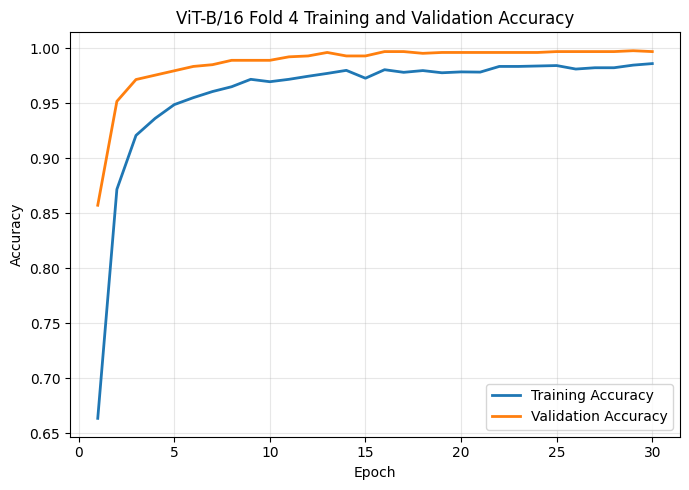

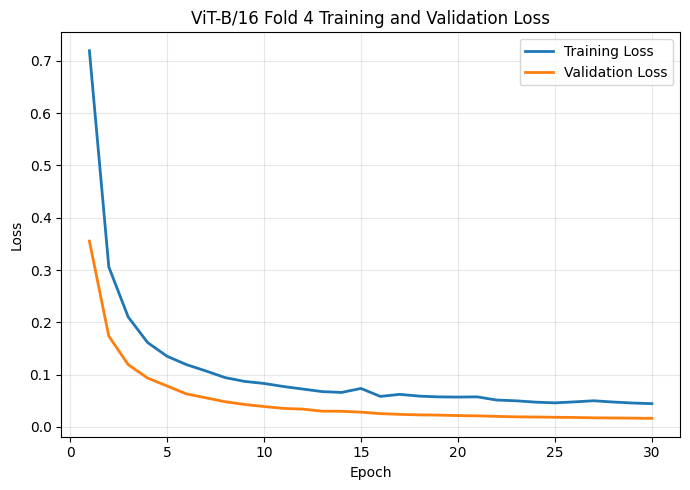


Validation Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,ViT-B/16,4,validation,0.016269,0.996825,0.995,0.998328,0.996661,0.999914,659,3,1,597,5885.178628,98.08631



Independent Test Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,ViT-B/16,4,test,0.022879,0.994604,0.996198,0.992424,0.994307,0.999802,582,2,4,524,5885.178628,98.08631



Saved model:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/saved_models/ViT-B16_fold_4.pth

Saved history:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/training_history/ViT-B16_fold_4_history.csv

Saved validation predictions:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_4_validation_predictions.csv

Saved test predictions:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_4_test_predictions.csv

Saved fold summary:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/metrics/ViT-B16_fold_4_summary.csv

ViT-B/16 FOLD 4 COMPLETED

STARTING ViT-B/16 FOLD 5/5
Training images: 5040
Validation images: 1259
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    661
no_encroachment         598
Name: count, dtype: int64


...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 5 | Epoch 30/30 - loss: 0.0439 - accuracy: 0.9869 - val_loss: 0.0263 - val_accuracy: 0.9889

Fold 5 training time: 85.42 minutes


Fold 5 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 5 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

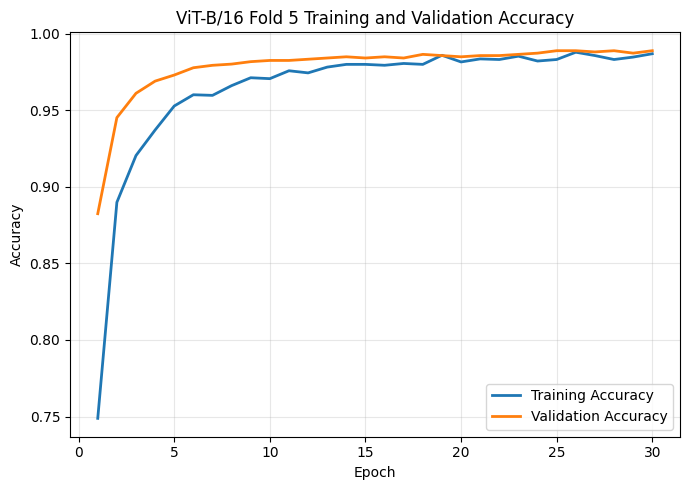

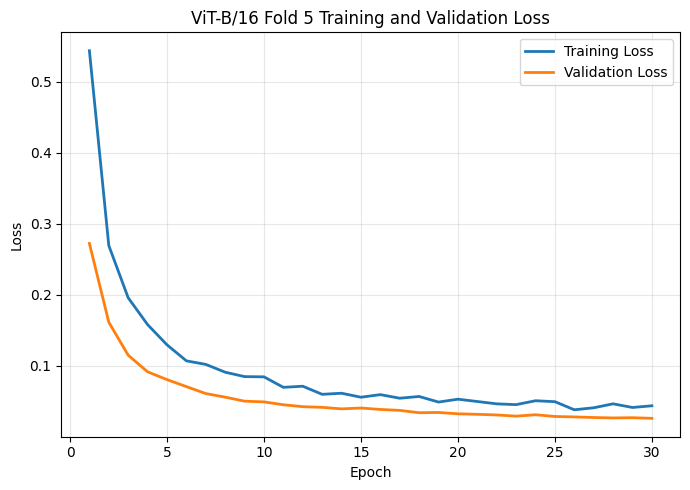


Validation Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,ViT-B/16,5,validation,0.026263,0.98888,0.991582,0.98495,0.988255,0.999656,656,5,9,589,5125.09065,85.418177



Independent Test Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,ViT-B/16,5,test,0.023092,0.993705,0.99619,0.99053,0.993352,0.999754,582,2,5,523,5125.09065,85.418177



Saved model:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/saved_models/ViT-B16_fold_5.pth

Saved history:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/training_history/ViT-B16_fold_5_history.csv

Saved validation predictions:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_5_validation_predictions.csv

Saved test predictions:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_5_test_predictions.csv

Saved fold summary:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16/metrics/ViT-B16_fold_5_summary.csv

ViT-B/16 FOLD 5 COMPLETED

ViT-B/16 FOLD 4 AND FOLD 5 COMPLETED

Fold 4 and Fold 5 outputs saved inside:
/content/drive/MyDrive/reviewer_final_results/06_ViT_B16

Fold 1–3 were NOT retrained.
Only Fold 4 and Fold 5 were trained in this run.


In [9]:
# ============================================================
# ViT-B/16 — CELL 3
# FOLD 4 AND FOLD 5 ONLY
# Same original training/evaluation/saving logic
# ============================================================


# ============================================================
# 1. SAVE TRAINING HISTORY AND FOLD GRAPHS
# ============================================================

def save_history_and_graphs(
    history_dictionary,
    fold_number
):

    history_df = pd.DataFrame(
        history_dictionary
    )


    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )


    # --------------------------------------------------------
    # Save history CSV
    # --------------------------------------------------------

    history_path = (
        HISTORY_DIR /
        f"ViT-B16_fold_{fold_number}_history.csv"
    )


    history_df.to_csv(
        history_path,
        index=False
    )


    # --------------------------------------------------------
    # Accuracy curve
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )


    plt.plot(
        history_df["epoch"],
        history_df["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )


    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        linewidth=2,
        label="Validation Accuracy"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Accuracy"
    )


    plt.title(
        f"ViT-B/16 Fold {fold_number} "
        f"Training and Validation Accuracy"
    )


    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    accuracy_path = (
        FIGURE_DIR /
        f"ViT-B16_fold_{fold_number}_accuracy.png"
    )


    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    # --------------------------------------------------------
    # Loss curve
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )


    plt.plot(
        history_df["epoch"],
        history_df["loss"],
        linewidth=2,
        label="Training Loss"
    )


    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        linewidth=2,
        label="Validation Loss"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Loss"
    )


    plt.title(
        f"ViT-B/16 Fold {fold_number} "
        f"Training and Validation Loss"
    )


    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    loss_path = (
        FIGURE_DIR /
        f"ViT-B16_fold_{fold_number}_loss.png"
    )


    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    return {

        "history_dataframe":
            history_df,

        "history_path":
            history_path,

        "accuracy_path":
            accuracy_path,

        "loss_path":
            loss_path
    }


# ============================================================
# 2. SAVE VALIDATION / TEST PREDICTIONS
# ============================================================

def save_predictions(
    evaluation_result,
    fold_number,
    dataset_name
):

    prediction_df = pd.DataFrame({

        "image_path":
            evaluation_result[
                "image_paths"
            ],

        "label":
            evaluation_result[
                "true_labels"
            ],

        "class_name": [

            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "true_labels"
            ]
        ],

        "predicted_probability_class_1":
            evaluation_result[
                "probabilities"
            ],

        "predicted_label":
            evaluation_result[
                "predictions"
            ],

        "predicted_class_name": [

            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "predictions"
            ]
        ]
    })


    prediction_df[
        "correct_prediction"
    ] = (

        prediction_df[
            "label"
        ].astype(int)

        ==

        prediction_df[
            "predicted_label"
        ].astype(int)
    )


    prediction_path = (
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"{dataset_name}_predictions.csv"
    )


    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    return (
        prediction_df,
        prediction_path
    )


# ============================================================
# 3. SAVE MODEL CHECKPOINT
# ============================================================

def save_checkpoint(
    model,
    fold_number
):

    checkpoint_path = (
        MODEL_DIR /
        f"ViT-B16_fold_{fold_number}.pth"
    )


    checkpoint = {

        "model_name":
            MODEL_NAME,

        "timm_model_name":
            TIMM_MODEL_NAME,

        "fold":
            int(
                fold_number
            ),

        "image_size":
            IMG_SIZE,

        "batch_size":
            BATCH_SIZE,

        "epochs":
            EPOCHS,

        "learning_rate":
            LEARNING_RATE,

        "threshold":
            THRESHOLD,

        "class_names":
            CLASS_NAMES,

        "class_to_idx":
            CLASS_TO_IDX,

        "model_state_dict":
            model.state_dict()
    }


    torch.save(
        checkpoint,
        checkpoint_path
    )


    return checkpoint_path


# ============================================================
# 4. CREATE SUMMARY ROW
# ============================================================

def create_summary_row(
    evaluation_result,
    fold_number,
    dataset_name,
    training_time_seconds
):

    return {

        "model":
            MODEL_NAME,

        "fold":
            int(
                fold_number
            ),

        "dataset":
            dataset_name,

        "loss":
            float(
                evaluation_result[
                    "loss"
                ]
            ),

        "accuracy":
            float(
                evaluation_result[
                    "accuracy"
                ]
            ),

        "precision":
            float(
                evaluation_result[
                    "precision"
                ]
            ),

        "recall":
            float(
                evaluation_result[
                    "recall"
                ]
            ),

        "f1_score":
            float(
                evaluation_result[
                    "f1_score"
                ]
            ),

        "auc":
            float(
                evaluation_result[
                    "auc"
                ]
            ),

        "true_negative":
            int(
                evaluation_result[
                    "true_negative"
                ]
            ),

        "false_positive":
            int(
                evaluation_result[
                    "false_positive"
                ]
            ),

        "false_negative":
            int(
                evaluation_result[
                    "false_negative"
                ]
            ),

        "true_positive":
            int(
                evaluation_result[
                    "true_positive"
                ]
            ),

        "training_time_seconds":
            float(
                training_time_seconds
            ),

        "training_time_minutes":
            float(
                training_time_seconds /
                60
            )
    }


# ============================================================
# 5. ACTUAL TRAINING
# ONLY FOLD 4 AND FOLD 5
# ============================================================

all_summary_rows = []

completed_fold_results = {}


for fold_number in range(
    4,
    6
):

    print(
        "\n" +
        "=" * 80
    )

    print(
        f"STARTING ViT-B/16 "
        f"FOLD {fold_number}/{N_FOLDS}"
    )

    print(
        "=" * 80
    )


    # --------------------------------------------------------
    # Fold-specific train / validation split
    # --------------------------------------------------------

    fold_train_df = (
        development_df[

            development_df[
                "fold_id"
            ] != fold_number
        ]

        .reset_index(
            drop=True
        )
    )


    fold_validation_df = (
        development_df[

            development_df[
                "fold_id"
            ] == fold_number
        ]

        .reset_index(
            drop=True
        )
    )


    print(
        "Training images:",
        len(
            fold_train_df
        )
    )


    print(
        "Validation images:",
        len(
            fold_validation_df
        )
    )


    print(
        "Independent test images:",
        len(
            test_df
        )
    )


    print(
        "\nTraining class distribution:"
    )


    print(
        fold_train_df[
            "class_name"
        ].value_counts()
    )


    print(
        "\nValidation class distribution:"
    )


    print(
        fold_validation_df[
            "class_name"
        ].value_counts()
    )


    # --------------------------------------------------------
    # Create DataLoaders
    # --------------------------------------------------------

    (
        fold_train_dataset,
        fold_train_loader
    ) = create_dataloader(

        dataframe=fold_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    (
        fold_validation_dataset,
        fold_validation_loader
    ) = create_dataloader(

        dataframe=fold_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # --------------------------------------------------------
    # Reproducibility for current fold
    # --------------------------------------------------------

    set_seed(
        SEED +
        fold_number
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # BUILD FRESH ViT-B/16
    # --------------------------------------------------------

    model, criterion, optimizer = (
        build_vit_b16_model()
    )


    history_dictionary = {

        "loss":
            [],

        "accuracy":
            [],

        "val_loss":
            [],

        "val_accuracy":
            []
    }


    # --------------------------------------------------------
    # Start fold training timer
    # --------------------------------------------------------

    training_start_time = (
        time.perf_counter()
    )


    # ========================================================
    # ACTUAL 30-EPOCH TRAINING LOOP
    # ========================================================

    for epoch_number in range(
        1,
        EPOCHS + 1
    ):

        training_result = train_one_epoch(

            model=model,

            dataloader=fold_train_loader,

            criterion=criterion,

            optimizer=optimizer,

            epoch_number=epoch_number
        )


        # ----------------------------------------------------
        # Validation after current epoch
        # ----------------------------------------------------

        validation_result = evaluate_model(

            model=model,

            dataloader=fold_validation_loader,

            criterion=criterion,

            description=(
                f"Epoch {epoch_number:02d}/"
                f"{EPOCHS} Validation"
            )
        )


        # ----------------------------------------------------
        # Store epoch history
        # ----------------------------------------------------

        history_dictionary[
            "loss"
        ].append(
            training_result[
                "loss"
            ]
        )


        history_dictionary[
            "accuracy"
        ].append(
            training_result[
                "accuracy"
            ]
        )


        history_dictionary[
            "val_loss"
        ].append(
            validation_result[
                "loss"
            ]
        )


        history_dictionary[
            "val_accuracy"
        ].append(
            validation_result[
                "accuracy"
            ]
        )


        # ----------------------------------------------------
        # Epoch output
        # ----------------------------------------------------

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch_number:02d}/{EPOCHS} - "
            f"loss: "
            f"{training_result['loss']:.4f} - "
            f"accuracy: "
            f"{training_result['accuracy']:.4f} - "
            f"val_loss: "
            f"{validation_result['loss']:.4f} - "
            f"val_accuracy: "
            f"{validation_result['accuracy']:.4f}"
        )


    # --------------------------------------------------------
    # End training timer
    # --------------------------------------------------------

    training_time_seconds = (

        time.perf_counter() -

        training_start_time
    )


    training_time_minutes = (

        training_time_seconds /

        60
    )


    print(
        f"\nFold {fold_number} "
        f"training time: "
        f"{training_time_minutes:.2f} minutes"
    )


    # ========================================================
    # FINAL VALIDATION EVALUATION
    # ========================================================

    final_validation_result = evaluate_model(

        model=model,

        dataloader=fold_validation_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} "
            f"Final Validation"
        )
    )


    # ========================================================
    # INDEPENDENT TEST EVALUATION
    # ========================================================

    final_test_result = evaluate_model(

        model=model,

        dataloader=test_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} "
            f"Independent Test"
        )
    )


    # ========================================================
    # SAVE HISTORY + GRAPHS
    # ========================================================

    history_outputs = (
        save_history_and_graphs(

            history_dictionary=(
                history_dictionary
            ),

            fold_number=fold_number
        )
    )


    # ========================================================
    # SAVE VALIDATION PREDICTIONS
    # ========================================================

    (
        validation_prediction_df,
        validation_prediction_path
    ) = save_predictions(

        evaluation_result=(
            final_validation_result
        ),

        fold_number=fold_number,

        dataset_name="validation"
    )


    # ========================================================
    # SAVE INDEPENDENT TEST PREDICTIONS
    # ========================================================

    (
        test_prediction_df,
        test_prediction_path
    ) = save_predictions(

        evaluation_result=(
            final_test_result
        ),

        fold_number=fold_number,

        dataset_name="test"
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    checkpoint_path = save_checkpoint(

        model=model,

        fold_number=fold_number
    )


    # ========================================================
    # CREATE SUMMARY ROWS
    # ========================================================

    validation_summary = create_summary_row(

        evaluation_result=(
            final_validation_result
        ),

        fold_number=fold_number,

        dataset_name="validation",

        training_time_seconds=(
            training_time_seconds
        )
    )


    test_summary = create_summary_row(

        evaluation_result=(
            final_test_result
        ),

        fold_number=fold_number,

        dataset_name="test",

        training_time_seconds=(
            training_time_seconds
        )
    )


    fold_summary_df = pd.DataFrame([

        validation_summary,

        test_summary
    ])


    # ========================================================
    # SAVE CURRENT FOLD SUMMARY
    # ========================================================

    fold_summary_path = (
        METRIC_DIR /
        f"ViT-B16_fold_{fold_number}_summary.csv"
    )


    fold_summary_df.to_csv(
        fold_summary_path,
        index=False
    )


    all_summary_rows.extend([

        validation_summary,

        test_summary
    ])


    # ========================================================
    # KEEP CURRENT RUNTIME RESULTS
    # ========================================================

    completed_fold_results[
        fold_number
    ] = {

        "history":
            history_outputs[
                "history_dataframe"
            ],

        "validation_result":
            final_validation_result,

        "test_result":
            final_test_result,

        "summary":
            fold_summary_df,

        "checkpoint_path":
            checkpoint_path,

        "training_time_seconds":
            training_time_seconds
    }


    # ========================================================
    # SHOW CURRENT FOLD RESULTS
    # ========================================================

    print(
        "\nValidation Result:"
    )


    display(
        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "validation"
        ]
    )


    print(
        "\nIndependent Test Result:"
    )


    display(
        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "test"
        ]
    )


    print(
        "\nSaved model:"
    )

    print(
        checkpoint_path
    )


    print(
        "\nSaved history:"
    )

    print(
        history_outputs[
            "history_path"
        ]
    )


    print(
        "\nSaved validation predictions:"
    )

    print(
        validation_prediction_path
    )


    print(
        "\nSaved test predictions:"
    )

    print(
        test_prediction_path
    )


    print(
        "\nSaved fold summary:"
    )

    print(
        fold_summary_path
    )


    print(
        "\n" +
        "=" * 80
    )


    print(
        f"ViT-B/16 FOLD "
        f"{fold_number} COMPLETED"
    )


    print(
        "=" * 80
    )


    # ========================================================
    # CLEAN MEMORY BEFORE NEXT FOLD
    # ========================================================

    del model

    del criterion

    del optimizer

    del fold_train_loader

    del fold_validation_loader

    del fold_train_dataset

    del fold_validation_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# 6. FINAL OUTPUT FOR THIS RESUME RUN
# ============================================================

print(
    "\n" +
    "=" * 80
)


print(
    "ViT-B/16 FOLD 4 AND FOLD 5 COMPLETED"
)


print(
    "=" * 80
)


print(
    "\nFold 4 and Fold 5 outputs saved inside:"
)


print(
    MODEL_OUTPUT_DIR
)


print(
    "\nFold 1–3 were NOT retrained."
)


print(
    "Only Fold 4 and Fold 5 were trained in this run."
)

In [15]:
# ============================================================
# FIX ViT-B/16 PATHS FOR Brishty_ml SHARED SHORTCUT
# Run this BEFORE Cell 4
# ============================================================

from pathlib import Path


# ------------------------------------------------------------
# Search for an already-saved ViT fold file
# ------------------------------------------------------------

SEARCH_ROOTS = [
    Path("/content/drive/MyDrive"),
    Path("/content/drive/.shortcut-targets-by-id")
]


TARGET_FILE = "ViT-B16_fold_1_summary.csv"

FOUND_SUMMARY = None


for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    print("Searching:", root)

    for file_path in root.rglob(TARGET_FILE):

        if file_path.is_file():

            FOUND_SUMMARY = file_path
            break

    if FOUND_SUMMARY is not None:
        break


# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------

if FOUND_SUMMARY is None:

    raise FileNotFoundError(
        f"Could not locate {TARGET_FILE}"
    )


# ============================================================
# Automatically rebuild correct ViT folder paths
# ============================================================

# Example:
# .../06_ViT_B16/metrics/ViT-B16_fold_1_summary.csv

METRIC_DIR = FOUND_SUMMARY.parent

MODEL_OUTPUT_DIR = METRIC_DIR.parent

OUTPUT_DIR = MODEL_OUTPUT_DIR.parent


MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)

HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)

FIGURE_DIR = (
    MODEL_OUTPUT_DIR /
    "figures"
)

PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)


# ============================================================
# CHECK
# ============================================================

print("\n" + "=" * 75)
print("CORRECT ViT-B/16 PATHS FOUND")
print("=" * 75)

print("\nFold 1 summary:")
print(FOUND_SUMMARY)

print("\nOUTPUT_DIR:")
print(OUTPUT_DIR)

print("\nMODEL_OUTPUT_DIR:")
print(MODEL_OUTPUT_DIR)

print("\nMETRIC_DIR:")
print(METRIC_DIR)

print("\nHISTORY_DIR:")
print(HISTORY_DIR)

print("\nPREDICTION_DIR:")
print(PREDICTION_DIR)

print("\nMODEL_DIR:")
print(MODEL_DIR)


# Final verification

print("\nFold files check:")

for fold in range(1, 6):

    p = (
        METRIC_DIR /
        f"ViT-B16_fold_{fold}_summary.csv"
    )

    print(
        f"Fold {fold}:",
        p.exists()
    )

Searching: /content/drive/MyDrive
Searching: /content/drive/.shortcut-targets-by-id

CORRECT ViT-B/16 PATHS FOUND

Fold 1 summary:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/metrics/ViT-B16_fold_1_summary.csv

OUTPUT_DIR:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results

MODEL_OUTPUT_DIR:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16

METRIC_DIR:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/metrics

HISTORY_DIR:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/training_history

PREDICTION_DIR:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/predictions

MODEL_DIR:
/content/dri

ViT-B/16 FINAL POST-TRAINING ANALYSIS
Final result folder: /content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/final_standard_paper_results
All Fold 1–5 files found successfully.

Five-fold validation results:


,fold,loss,accuracy,precision,recall,f1_score,auc,training_time_minutes
0,1,0.025345,0.992063,0.994958,0.988314,0.991625,0.999631,92.273905
1,2,0.020881,0.992063,0.996627,0.986644,0.991611,0.999922,79.493780
2,3,0.028155,0.989683,0.996604,0.981605,0.989048,0.999689,80.454983
3,4,0.016269,0.996825,0.995000,0.998328,0.996661,0.999914,98.086310
4,5,0.026263,0.988880,0.991582,0.984950,0.988255,0.999656,85.418177



Performance Mean ± SD:


,Model,Loss,Accuracy (%),Precision (%),Recall (%),F1-Score (%),AUC
0,ViT-B/16,0.02 ± 0.00,99.19 ± 0.31,99.50 ± 0.21,98.80 ± 0.63,99.14 ± 0.33,1.00 ± 0.00



Accuracy 95% Confidence Interval:


,Model,Mean Accuracy (%),Standard Deviation (%),Standard Error (%),95% CI Lower (%),95% CI Upper (%),Paper Format
0,ViT-B/16,99.1903,0.309637,0.138474,98.805834,99.574765,99.19% (98.81%–99.57%)



Training Time Mean ± SD:


,Model,Mean Training Time (minutes),Training Time SD (minutes),Mean ± SD
0,ViT-B/16,87.145431,7.941935,87.15 ± 7.94


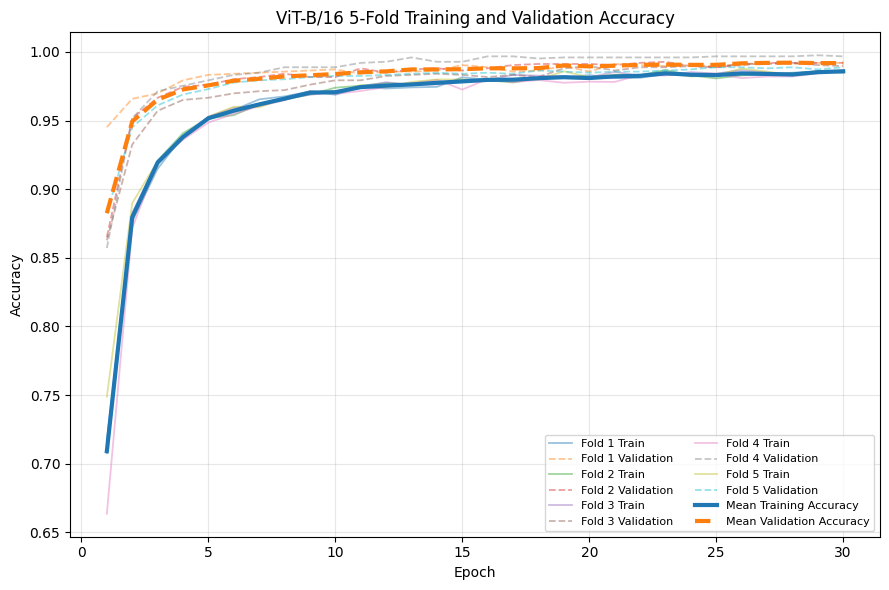

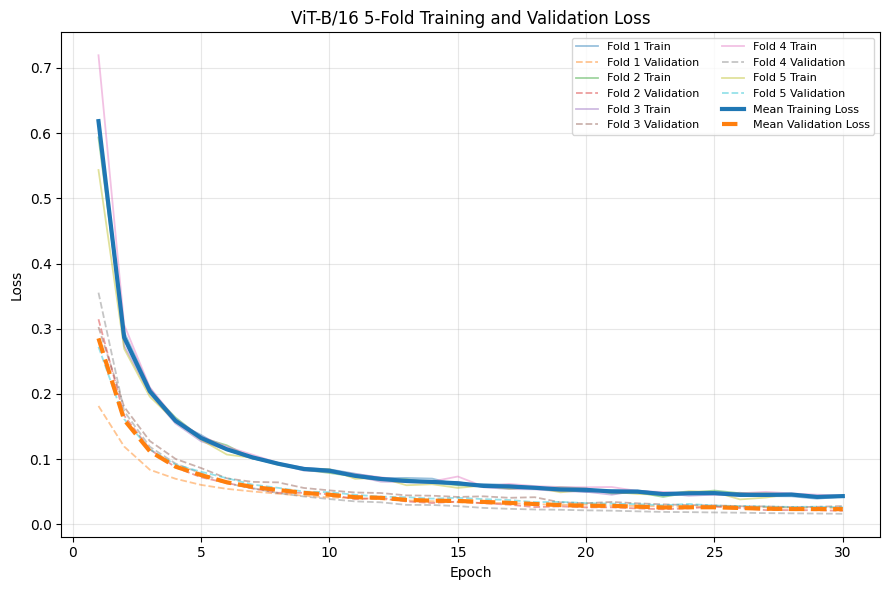

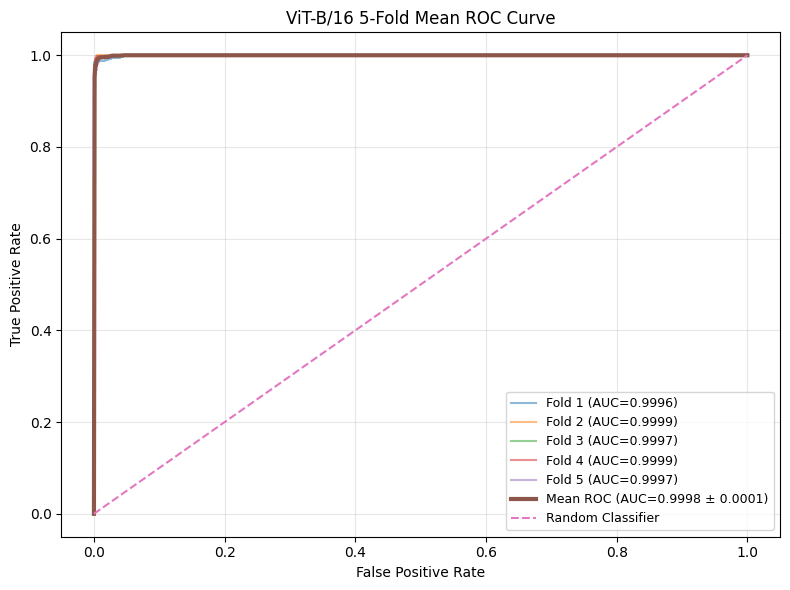

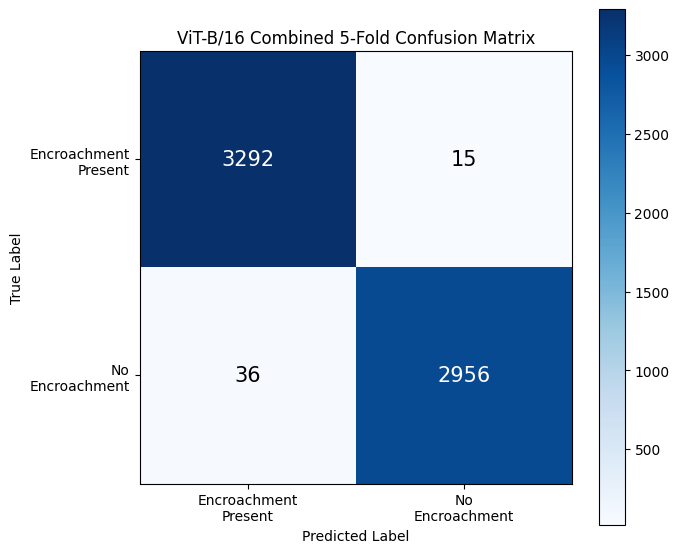

backbone.blocks.0.attn.attn_drop, backbone.blocks.1.attn.attn_drop, backbone.blocks.10.attn.attn_drop, backbone.blocks.11.attn.attn_drop, backbone.blocks.2.attn.attn_drop, backbone.blocks.3.attn.attn_drop, backbone.blocks.4.attn.attn_drop, backbone.blocks.5.attn.attn_drop, backbone.blocks.6.attn.attn_drop, backbone.blocks.7.attn.attn_drop, backbone.blocks.8.attn.attn_drop, backbone.blocks.9.attn.attn_drop



Computational Complexity:


,Model,Parameters (M),Trainable Parameters (M),Non-trainable Parameters (M),GFLOPs,Model Size (MB),Inference Time (ms/image),FPS,Training Time (minutes)
0,ViT-B/16,85.799425,0.000769,85.798656,16.866646,327.360322,19.282788,51.859721,87.15 ± 7.94



ViT-B/16 FINAL ANALYSIS COMPLETED

TABLES
1. Performance Mean ± SD:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/final_standard_paper_results/tables/ViT-B16_performance_mean_std.csv

2. Accuracy 95% CI:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/final_standard_paper_results/tables/ViT-B16_statistical_95CI.csv

3. Training Time Mean ± SD:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/final_standard_paper_results/tables/ViT-B16_training_time_mean_std.csv

4. ROC/AUC Summary:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_ml/reviewer_final_results/06_ViT_B16/final_standard_paper_results/tables/ViT-B16_ROC_AUC_summary.csv

5. Combined Confusion Matrix Values:
/content/drive/.shortcut-targets-by-id/1sMMjV4pBkIDz-l6Z4c844BzGGsrBG88D/Brishty_

In [16]:
# ============================================================
# ViT-B/16 — CELL 4
# FINAL POST-TRAINING PAPER-READY ANALYSIS
# Run after all 5 folds are completed
# ============================================================

from scipy import stats
from fvcore.nn import FlopCountAnalysis


# ============================================================
# 1. FINAL OUTPUT DIRECTORIES
# ============================================================

FINAL_RESULTS_DIR = (
    MODEL_OUTPUT_DIR /
    "final_standard_paper_results"
)

FINAL_TABLE_DIR = (
    FINAL_RESULTS_DIR /
    "tables"
)

FINAL_FIGURE_DIR = (
    FINAL_RESULTS_DIR /
    "figures"
)


FINAL_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 80)
print("ViT-B/16 FINAL POST-TRAINING ANALYSIS")
print("=" * 80)

print(
    "Final result folder:",
    FINAL_RESULTS_DIR
)


# ============================================================
# 2. VERIFY REQUIRED FILES
# ============================================================

def verify_required_file(
    file_path
):

    file_path = Path(
        file_path
    )

    if not file_path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n"
            f"{file_path}"
        )

    return file_path


for fold_number in range(
    1,
    N_FOLDS + 1
):

    verify_required_file(
        METRIC_DIR /
        f"ViT-B16_fold_{fold_number}_summary.csv"
    )

    verify_required_file(
        HISTORY_DIR /
        f"ViT-B16_fold_{fold_number}_history.csv"
    )

    verify_required_file(
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"validation_predictions.csv"
    )

    verify_required_file(
        MODEL_DIR /
        f"ViT-B16_fold_{fold_number}.pth"
    )


print(
    "All Fold 1–5 files found successfully."
)


# ============================================================
# 3. READ FIVE-FOLD VALIDATION RESULTS
# ============================================================

validation_rows = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"ViT-B16_fold_{fold_number}_summary.csv"
    )


    fold_summary_df = pd.read_csv(
        summary_path
    )


    validation_df = fold_summary_df[

        fold_summary_df[
            "dataset"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq(
            "validation"
        )
    ]


    if len(
        validation_df
    ) != 1:

        raise ValueError(
            f"Fold {fold_number} must contain "
            f"exactly one validation row."
        )


    row = (
        validation_df
        .iloc[0]
        .to_dict()
    )


    row[
        "fold"
    ] = fold_number


    validation_rows.append(
        row
    )


validation_metrics_df = (
    pd.DataFrame(
        validation_rows
    )
    .sort_values(
        "fold"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nFive-fold validation results:"
)


display(
    validation_metrics_df[
        [
            "fold",
            "loss",
            "accuracy",
            "precision",
            "recall",
            "f1_score",
            "auc",
            "training_time_minutes"
        ]
    ]
)


# ============================================================
# 4. MEAN ± STANDARD DEVIATION
# ============================================================

metric_mapping = {

    "Loss":
        "loss",

    "Accuracy (%)":
        "accuracy",

    "Precision (%)":
        "precision",

    "Recall (%)":
        "recall",

    "F1-Score (%)":
        "f1_score",

    "AUC":
        "auc"
}


performance_record = {

    "Model":
        MODEL_NAME
}


for display_name, column_name in (
    metric_mapping.items()
):

    values = (
        validation_metrics_df[
            column_name
        ]
        .astype(float)
        .values
    )


    if display_name in [

        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"

    ]:

        values = (
            values *
            100
        )


    mean_value = float(
        np.mean(
            values
        )
    )


    standard_deviation = float(
        np.std(
            values,
            ddof=1
        )
    )


    performance_record[
        display_name
    ] = (
        f"{mean_value:.2f} ± "
        f"{standard_deviation:.2f}"
    )


performance_table_df = pd.DataFrame([
    performance_record
])


performance_table_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_performance_mean_std.csv"
)


performance_table_df.to_csv(
    performance_table_path,
    index=False
)


print(
    "\nPerformance Mean ± SD:"
)


display(
    performance_table_df
)


# ============================================================
# 5. ACCURACY 95% CONFIDENCE INTERVAL
# ============================================================

accuracy_values = (

    validation_metrics_df[
        "accuracy"
    ]
    .astype(float)
    .values *

    100
)


mean_accuracy = float(
    np.mean(
        accuracy_values
    )
)


accuracy_sd = float(
    np.std(
        accuracy_values,
        ddof=1
    )
)


accuracy_se = (

    accuracy_sd /

    np.sqrt(
        N_FOLDS
    )
)


t_critical = stats.t.ppf(

    0.975,

    df=(
        N_FOLDS -
        1
    )
)


confidence_margin = (

    t_critical *

    accuracy_se
)


ci_lower = (

    mean_accuracy -

    confidence_margin
)


ci_upper = (

    mean_accuracy +

    confidence_margin
)


confidence_interval_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Accuracy (%)":
            mean_accuracy,

        "Standard Deviation (%)":
            accuracy_sd,

        "Standard Error (%)":
            accuracy_se,

        "95% CI Lower (%)":
            ci_lower,

        "95% CI Upper (%)":
            ci_upper,

        "Paper Format":
            (
                f"{mean_accuracy:.2f}% "
                f"({ci_lower:.2f}%–"
                f"{ci_upper:.2f}%)"
            )
    }
])


confidence_interval_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_statistical_95CI.csv"
)


confidence_interval_df.to_csv(
    confidence_interval_path,
    index=False
)


print(
    "\nAccuracy 95% Confidence Interval:"
)


display(
    confidence_interval_df
)


# ============================================================
# 6. TRAINING TIME MEAN ± SD
# ============================================================

training_time_values = (

    validation_metrics_df[
        "training_time_minutes"
    ]
    .astype(float)
    .values
)


mean_training_time = float(
    np.mean(
        training_time_values
    )
)


training_time_sd = float(
    np.std(
        training_time_values,
        ddof=1
    )
)


training_time_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Training Time (minutes)":
            mean_training_time,

        "Training Time SD (minutes)":
            training_time_sd,

        "Mean ± SD":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


training_time_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_training_time_mean_std.csv"
)


training_time_df.to_csv(
    training_time_path,
    index=False
)


print(
    "\nTraining Time Mean ± SD:"
)


display(
    training_time_df
)


# ============================================================
# 7. READ ALL FIVE TRAINING HISTORIES
# ============================================================

training_accuracy_list = []

validation_accuracy_list = []

training_loss_list = []

validation_loss_list = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    history_path = (
        HISTORY_DIR /
        f"ViT-B16_fold_{fold_number}_history.csv"
    )


    history_df = pd.read_csv(
        history_path
    )


    required_columns = {

        "epoch",
        "loss",
        "accuracy",
        "val_loss",
        "val_accuracy"
    }


    if not required_columns.issubset(
        history_df.columns
    ):

        raise KeyError(
            f"Fold {fold_number} history "
            f"is missing required columns."
        )


    training_accuracy_list.append(

        history_df[
            "accuracy"
        ]
        .astype(float)
        .values
    )


    validation_accuracy_list.append(

        history_df[
            "val_accuracy"
        ]
        .astype(float)
        .values
    )


    training_loss_list.append(

        history_df[
            "loss"
        ]
        .astype(float)
        .values
    )


    validation_loss_list.append(

        history_df[
            "val_loss"
        ]
        .astype(float)
        .values
    )


training_accuracy_matrix = np.vstack(
    training_accuracy_list
)


validation_accuracy_matrix = np.vstack(
    validation_accuracy_list
)


training_loss_matrix = np.vstack(
    training_loss_list
)


validation_loss_matrix = np.vstack(
    validation_loss_list
)


number_of_epochs = (
    training_accuracy_matrix.shape[
        1
    ]
)


epochs_array = np.arange(
    1,
    number_of_epochs + 1
)


# ============================================================
# 8. FIVE-FOLD MEAN ACCURACY CURVES
# ============================================================

mean_training_accuracy = np.mean(
    training_accuracy_matrix,
    axis=0
)


mean_validation_accuracy = np.mean(
    validation_accuracy_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_accuracy,
    linewidth=3,
    label="Mean Training Accuracy"
)


plt.plot(
    epochs_array,
    mean_validation_accuracy,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "ViT-B/16 5-Fold Training and Validation Accuracy"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


accuracy_curve_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_5fold_mean_accuracy_curves.png"
)


plt.savefig(
    accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 9. FIVE-FOLD MEAN LOSS CURVES
# ============================================================

mean_training_loss = np.mean(
    training_loss_matrix,
    axis=0
)


mean_validation_loss = np.mean(
    validation_loss_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_loss,
    linewidth=3,
    label="Mean Training Loss"
)


plt.plot(
    epochs_array,
    mean_validation_loss,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "ViT-B/16 5-Fold Training and Validation Loss"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


loss_curve_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_5fold_mean_loss_curves.png"
)


plt.savefig(
    loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 10. FIVE-FOLD ROC CURVES + MEAN ROC
# ============================================================

mean_fpr = np.linspace(
    0,
    1,
    1000
)


interpolated_tprs = []

fold_auc_values = []


plt.figure(
    figsize=(8, 6)
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (
        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    probabilities = (
        prediction_df[
            "predicted_probability_class_1"
        ]
        .astype(float)
        .values
    )


    (
        fpr,
        tpr,
        _
    ) = roc_curve(
        true_labels,
        probabilities
    )


    fold_auc = roc_auc_score(
        true_labels,
        probabilities
    )


    fold_auc_values.append(
        fold_auc
    )


    interpolated_tpr = np.interp(
        mean_fpr,
        fpr,
        tpr
    )


    interpolated_tpr[
        0
    ] = 0.0


    interpolated_tprs.append(
        interpolated_tpr
    )


    plt.plot(
        fpr,
        tpr,
        alpha=0.50,
        linewidth=1.5,
        label=(
            f"Fold {fold_number} "
            f"(AUC={fold_auc:.4f})"
        )
    )


mean_tpr = np.mean(
    interpolated_tprs,
    axis=0
)


mean_tpr[
    0
] = 0.0


mean_tpr[
    -1
] = 1.0


mean_auc = float(
    np.mean(
        fold_auc_values
    )
)


auc_sd = float(
    np.std(
        fold_auc_values,
        ddof=1
    )
)


plt.plot(
    mean_fpr,
    mean_tpr,
    linewidth=3,
    label=(
        f"Mean ROC "
        f"(AUC={mean_auc:.4f} ± "
        f"{auc_sd:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ViT-B/16 5-Fold Mean ROC Curve"
)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


roc_curve_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_5fold_mean_ROC_curve.png"
)


plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 11. SAVE ROC/AUC SUMMARY TABLE
# ============================================================

roc_auc_summary_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean AUC":
            mean_auc,

        "AUC SD":
            auc_sd,

        "Mean ± SD":
            (
                f"{mean_auc:.4f} ± "
                f"{auc_sd:.4f}"
            )
    }
])


roc_auc_summary_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_ROC_AUC_summary.csv"
)


roc_auc_summary_df.to_csv(
    roc_auc_summary_path,
    index=False
)


# ============================================================
# 12. COMBINED FIVE-FOLD CONFUSION MATRIX
# ============================================================

combined_confusion_matrix = np.zeros(
    (
        2,
        2
    ),
    dtype=int
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (
        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    predicted_labels = (
        prediction_df[
            "predicted_label"
        ]
        .astype(int)
        .values
    )


    fold_cm = confusion_matrix(

        true_labels,

        predicted_labels,

        labels=[
            0,
            1
        ]
    )


    combined_confusion_matrix += (
        fold_cm
    )


plt.figure(
    figsize=(7, 6)
)


plt.imshow(
    combined_confusion_matrix,
    interpolation="nearest",
    cmap="Blues"
)


plt.colorbar()


display_class_names = [
    "Encroachment\nPresent",
    "No\nEncroachment"
]


plt.xticks(
    [0, 1],
    display_class_names
)


plt.yticks(
    [0, 1],
    display_class_names
)


matrix_threshold = (
    combined_confusion_matrix.max() /
    2.0
)


for row_index in range(
    2
):

    for column_index in range(
        2
    ):

        value = int(
            combined_confusion_matrix[
                row_index,
                column_index
            ]
        )


        plt.text(
            column_index,
            row_index,
            str(value),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=15,
            color=(
                "white"
                if value >
                matrix_threshold
                else "black"
            )
        )


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "ViT-B/16 Combined 5-Fold Confusion Matrix"
)

plt.tight_layout()


confusion_matrix_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_combined_5fold_confusion_matrix.png"
)


plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 13. SAVE CONFUSION MATRIX VALUES
# ============================================================

confusion_values_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "True Negative":
            int(
                combined_confusion_matrix[
                    0,
                    0
                ]
            ),

        "False Positive":
            int(
                combined_confusion_matrix[
                    0,
                    1
                ]
            ),

        "False Negative":
            int(
                combined_confusion_matrix[
                    1,
                    0
                ]
            ),

        "True Positive":
            int(
                combined_confusion_matrix[
                    1,
                    1
                ]
            )
    }
])


confusion_values_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_combined_confusion_matrix_values.csv"
)


confusion_values_df.to_csv(
    confusion_values_path,
    index=False
)


# ============================================================
# 14. LOAD FOLD 1 MODEL FOR COMPLEXITY ANALYSIS
# ============================================================

complexity_model, _, _ = (
    build_vit_b16_model()
)


fold_1_checkpoint_path = (
    MODEL_DIR /
    "ViT-B16_fold_1.pth"
)


fold_1_checkpoint = torch.load(
    fold_1_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)


complexity_model.load_state_dict(
    fold_1_checkpoint[
        "model_state_dict"
    ]
)


complexity_model = complexity_model.to(
    DEVICE
)


complexity_model.eval()


# ============================================================
# 15. PARAMETER COUNT
# ============================================================

total_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
    if parameter.requires_grad
)


non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)


# ============================================================
# 16. MODEL CHECKPOINT SIZE
# ============================================================

model_size_mb = (

    fold_1_checkpoint_path
    .stat()
    .st_size /

    (1024 ** 2)
)


# ============================================================
# 17. GFLOPs
# ============================================================

try:

    dummy_input = torch.zeros(

        (
            1,
            3,
            IMG_SIZE,
            IMG_SIZE
        ),

        dtype=torch.float32,

        device=DEVICE
    )


    flop_analysis = FlopCountAnalysis(
        complexity_model,
        dummy_input
    )


    total_flops = float(
        flop_analysis.total()
    )


    gflops = (
        total_flops /
        1e9
    )


except Exception as error:

    print(
        "\nGFLOPs calculation warning:"
    )

    print(
        error
    )

    gflops = np.nan


# ============================================================
# 18. INFERENCE TIME + FPS
# ============================================================

# Warm-up

with torch.no_grad():

    for batch_index, batch in enumerate(
        test_loader
    ):

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        _ = complexity_model(
            images
        )


        if batch_index >= 4:

            break


if torch.cuda.is_available():

    torch.cuda.synchronize()


inference_trial_times = []


for trial_number in range(
    5
):

    start_time = (
        time.perf_counter()
    )


    with torch.no_grad():

        for batch in test_loader:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            _ = complexity_model(
                images
            )


    if torch.cuda.is_available():

        torch.cuda.synchronize()


    inference_trial_times.append(

        time.perf_counter() -

        start_time
    )


mean_inference_seconds = float(
    np.mean(
        inference_trial_times
    )
)


inference_ms_per_image = (

    mean_inference_seconds /

    len(
        test_dataset
    ) *

    1000
)


fps = (

    len(
        test_dataset
    ) /

    mean_inference_seconds
)


# ============================================================
# 19. COMPUTATIONAL COMPLEXITY TABLE
# ============================================================

complexity_table_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Parameters (M)":
            total_parameters /
            1e6,

        "Trainable Parameters (M)":
            trainable_parameters /
            1e6,

        "Non-trainable Parameters (M)":
            non_trainable_parameters /
            1e6,

        "GFLOPs":
            gflops,

        "Model Size (MB)":
            model_size_mb,

        "Inference Time (ms/image)":
            inference_ms_per_image,

        "FPS":
            fps,

        "Training Time (minutes)":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


complexity_table_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_computational_complexity.csv"
)


complexity_table_df.to_csv(
    complexity_table_path,
    index=False
)


print(
    "\nComputational Complexity:"
)


display(
    complexity_table_df
)


# ============================================================
# 20. CLEAN MEMORY
# ============================================================

del complexity_model


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ============================================================
# 21. FINAL OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "ViT-B/16 FINAL ANALYSIS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nTABLES"
)


print(
    "1. Performance Mean ± SD:"
)

print(
    performance_table_path
)


print(
    "\n2. Accuracy 95% CI:"
)

print(
    confidence_interval_path
)


print(
    "\n3. Training Time Mean ± SD:"
)

print(
    training_time_path
)


print(
    "\n4. ROC/AUC Summary:"
)

print(
    roc_auc_summary_path
)


print(
    "\n5. Combined Confusion Matrix Values:"
)

print(
    confusion_values_path
)


print(
    "\n6. Computational Complexity:"
)

print(
    complexity_table_path
)


print(
    "\nFIGURES"
)


print(
    "7. Mean Accuracy Curves:"
)

print(
    accuracy_curve_path
)


print(
    "\n8. Mean Loss Curves:"
)

print(
    loss_curve_path
)


print(
    "\n9. Mean ROC Curve:"
)

print(
    roc_curve_path
)


print(
    "\n10. Combined Confusion Matrix:"
)

print(
    confusion_matrix_path
)


print(
    "\nAll final ViT-B/16 results saved inside:"
)

print(
    FINAL_RESULTS_DIR
)


print(
    "\nMcNemar test should be performed later "
    "between the final comparison models."
)


print(
    "Grad-CAM / Grad-CAM++ should be performed "
    "later only for the selected best/proposed model."
)